# AeroGuard AI · NASA C-MAPSS

This notebook extends the original AEROPREDICT EDA with the training, evaluation and uncertainty analyses for AeroGuard AI. C-MAPSS contains simulated turbofan telemetry from NASA Ames.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 5)

print('Libraries loaded successfully')

Libraries loaded successfully


In [2]:
BASE_COLUMNS = ['unit_id', 'cycle', 'setting_1', 'setting_2', 'setting_3']
SENSOR_COLUMNS = [f'sensor_{i}' for i in range(1, 22)]
ALL_COLUMNS = BASE_COLUMNS + SENSOR_COLUMNS

def read_cmapss_file(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep=r'\s+', header=None, engine='python')
    df = df.dropna(axis=1, how='all')

    if df.shape[1] != len(ALL_COLUMNS):
        raise ValueError(f'Unexpected column count in {path.name}: {df.shape[1]}')

    df.columns = ALL_COLUMNS
    return df

def build_train_rul(train_df: pd.DataFrame) -> pd.DataFrame:
    max_cycle_per_unit = train_df.groupby('unit_id')['cycle'].max()
    out = train_df.copy()
    out['max_cycle'] = out['unit_id'].map(max_cycle_per_unit)
    out['rul'] = out['max_cycle'] - out['cycle']
    return out

print('Column and helper setup complete')

Column and helper setup complete


In [3]:
project_root = Path.cwd()
if not (project_root / 'data').exists():
    project_root = project_root.parent

data_dir = project_root / 'data'
assert data_dir.exists(), f'Data directory not found: {data_dir}'

subsets = ['FD001', 'FD002', 'FD003', 'FD004']

print('Project root: .')
print('Data directory: data/')
print('Available files:')
for p in sorted(data_dir.glob('*.txt')):
    print(' -', p.name)

Project root: .
Data directory: data/
Available files:
 - readme.txt
 - RUL_FD001.txt
 - RUL_FD002.txt
 - RUL_FD003.txt
 - RUL_FD004.txt
 - test_FD001.txt
 - test_FD002.txt
 - test_FD003.txt
 - test_FD004.txt
 - train_FD001.txt
 - train_FD002.txt
 - train_FD003.txt
 - train_FD004.txt


In [4]:
dataset = {}

for ds in subsets:
    train_path = data_dir / f'train_{ds}.txt'
    test_path = data_dir / f'test_{ds}.txt'
    rul_path = data_dir / f'RUL_{ds}.txt'

    train_df = read_cmapss_file(train_path)
    test_df = read_cmapss_file(test_path)
    rul_df = pd.read_csv(rul_path, sep=r'\s+', header=None, engine='python').dropna(axis=1, how='all')
    rul_df.columns = ['rul']

    dataset[ds] = {
        'train': train_df,
        'test': test_df,
        'rul': rul_df
    }

print('Datasets loaded')
for ds, d in dataset.items():
    print(f"{ds}: train={d['train'].shape}, test={d['test'].shape}, rul={d['rul'].shape}")

Datasets loaded
FD001: train=(20631, 26), test=(13096, 26), rul=(100, 1)
FD002: train=(53759, 26), test=(33991, 26), rul=(259, 1)
FD003: train=(24720, 26), test=(16596, 26), rul=(100, 1)
FD004: train=(61249, 26), test=(41214, 26), rul=(248, 1)


In [5]:
summary_rows = []
for ds, d in dataset.items():
    train_df = d['train']
    test_df = d['test']
    rul_df = d['rul']

    summary_rows.append({
        'dataset': ds,
        'train_rows': len(train_df),
        'test_rows': len(test_df),
        'train_engines': train_df['unit_id'].nunique(),
        'test_engines': test_df['unit_id'].nunique(),
        'train_cycle_min': int(train_df['cycle'].min()),
        'train_cycle_max': int(train_df['cycle'].max()),
        'test_cycle_min': int(test_df['cycle'].min()),
        'test_cycle_max': int(test_df['cycle'].max()),
        'rul_targets': len(rul_df)
    })

summary_df = pd.DataFrame(summary_rows).sort_values('dataset').reset_index(drop=True)
summary_df

,dataset,train_rows,test_rows,train_engines,test_engines,train_cycle_min,train_cycle_max,test_cycle_min,test_cycle_max,rul_targets
0,FD001,20631,13096,100,100,1,362,1,303,100
1,FD002,53759,33991,260,259,1,378,1,367,259
2,FD003,24720,16596,100,100,1,525,1,475,100
3,FD004,61249,41214,249,248,1,543,1,486,248


## Focus Dataset for Detailed EDA
Set `focus_ds` to any subset (`FD001`, `FD002`, `FD003`, `FD004`).

In [6]:
focus_ds = 'FD001'
train_df = dataset[focus_ds]['train'].copy()
test_df = dataset[focus_ds]['test'].copy()
rul_df = dataset[focus_ds]['rul'].copy()

train_with_rul = build_train_rul(train_df)

print('Focus dataset:', focus_ds)
print('Train shape:', train_df.shape)
print('Test shape:', test_df.shape)
print('RUL labels shape:', rul_df.shape)
train_df.head()

Focus dataset: FD001
Train shape: (20631, 26)
Test shape: (13096, 26)
RUL labels shape: (100, 1)


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [7]:
quality_df = pd.DataFrame({
    'column': train_df.columns,
    'dtype': [str(train_df[c].dtype) for c in train_df.columns],
    'missing_count': [int(train_df[c].isna().sum()) for c in train_df.columns],
    'missing_pct': [float(train_df[c].isna().mean() * 100) for c in train_df.columns],
    'n_unique': [int(train_df[c].nunique()) for c in train_df.columns]
})

print('Duplicate rows in train:', int(train_df.duplicated().sum()))
quality_df

Duplicate rows in train: 0


,column,dtype,missing_count,missing_pct,n_unique
0,unit_id,int64,0,0.0,100
1,cycle,int64,0,0.0,362
2,setting_1,float64,0,0.0,158
3,setting_2,float64,0,0.0,13
4,setting_3,float64,0,0.0,1
5,sensor_1,float64,0,0.0,1
6,sensor_2,float64,0,0.0,310
7,sensor_3,float64,0,0.0,3012
8,sensor_4,float64,0,0.0,4051
9,sensor_5,float64,0,0.0,1


In [8]:
life_stats = train_df.groupby('unit_id')['cycle'].max().describe().to_frame('train_lifecycle_length')
life_stats

,train_lifecycle_length
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


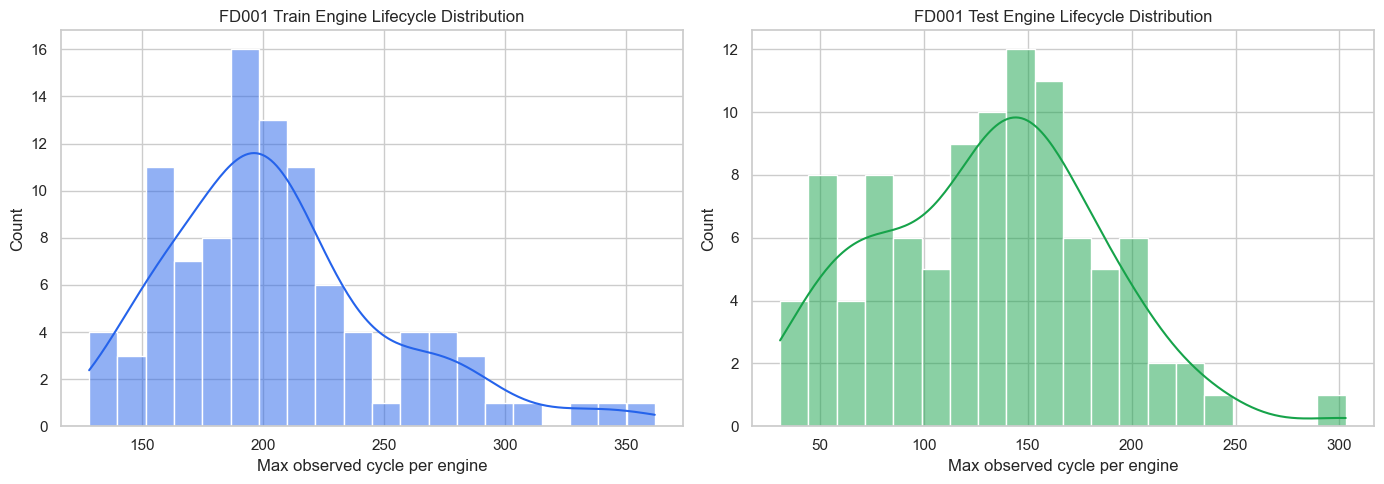

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_life = train_df.groupby('unit_id')['cycle'].max()
test_life = test_df.groupby('unit_id')['cycle'].max()

sns.histplot(train_life, bins=20, kde=True, ax=axes[0], color='#2563eb')
axes[0].set_title(f'{focus_ds} Train Engine Lifecycle Distribution')
axes[0].set_xlabel('Max observed cycle per engine')

sns.histplot(test_life, bins=20, kde=True, ax=axes[1], color='#16a34a')
axes[1].set_title(f'{focus_ds} Test Engine Lifecycle Distribution')
axes[1].set_xlabel('Max observed cycle per engine')

plt.tight_layout()
plt.show()

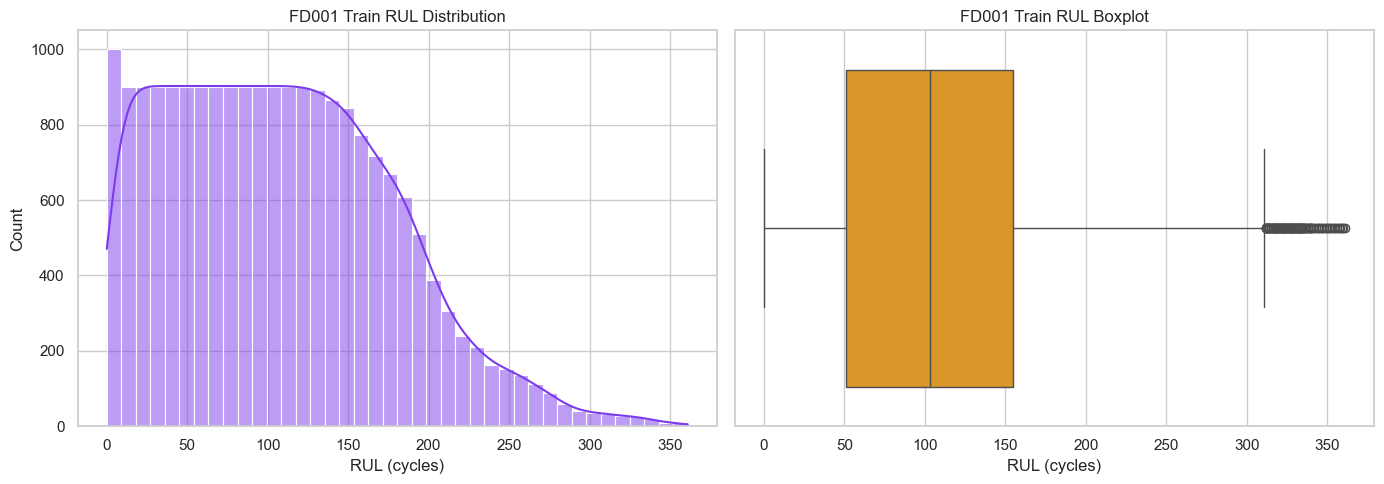

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=train_with_rul, x='rul', bins=40, kde=True, ax=axes[0], color='#7c3aed')
axes[0].set_title(f'{focus_ds} Train RUL Distribution')
axes[0].set_xlabel('RUL (cycles)')

sns.boxplot(x=train_with_rul['rul'], ax=axes[1], color='#f59e0b')
axes[1].set_title(f'{focus_ds} Train RUL Boxplot')
axes[1].set_xlabel('RUL (cycles)')

plt.tight_layout()
plt.show()

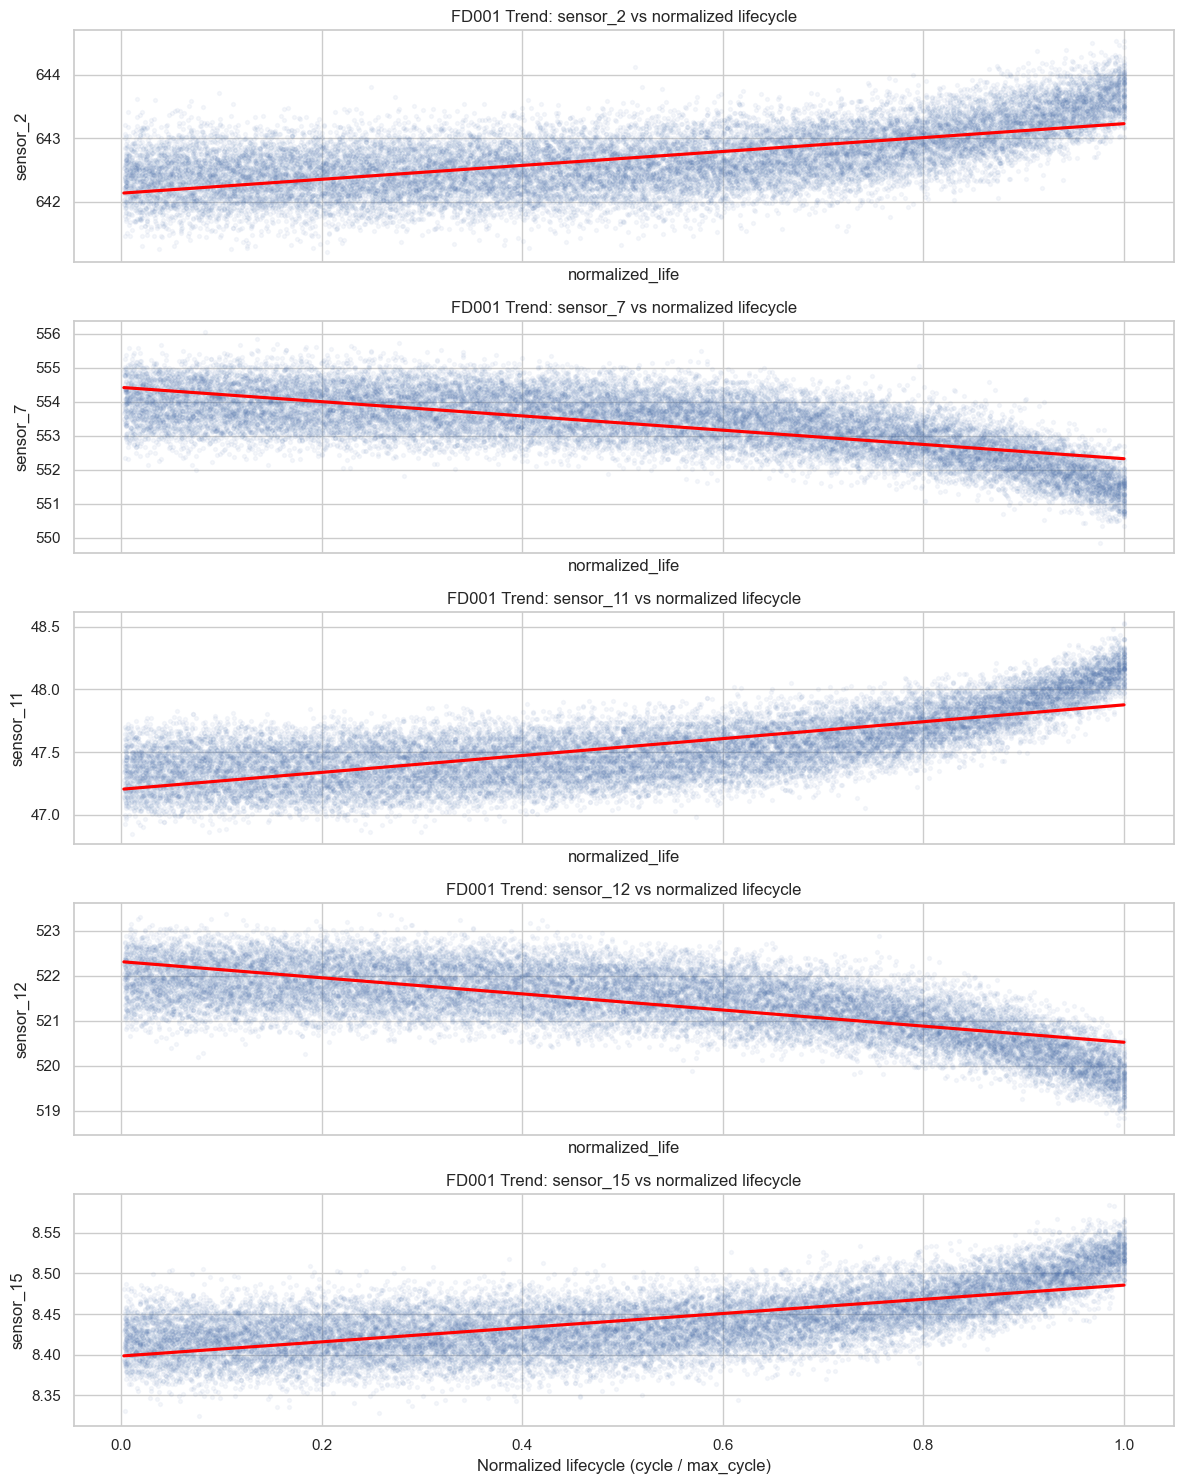

In [11]:
selected_sensors = ['sensor_2', 'sensor_7', 'sensor_11', 'sensor_12', 'sensor_15']

trend_df = train_with_rul.copy()
trend_df['normalized_life'] = trend_df['cycle'] / trend_df['max_cycle']

fig, axes = plt.subplots(len(selected_sensors), 1, figsize=(12, 3 * len(selected_sensors)), sharex=True)

if len(selected_sensors) == 1:
    axes = [axes]

for ax, s in zip(axes, selected_sensors):
    sampled = trend_df[['normalized_life', s]].sample(min(25000, len(trend_df)), random_state=42)
    sns.regplot(data=sampled, x='normalized_life', y=s, scatter_kws={'alpha': 0.05, 's': 8}, line_kws={'color': 'red'}, ax=ax)
    ax.set_title(f'{focus_ds} Trend: {s} vs normalized lifecycle')

axes[-1].set_xlabel('Normalized lifecycle (cycle / max_cycle)')
plt.tight_layout()
plt.show()

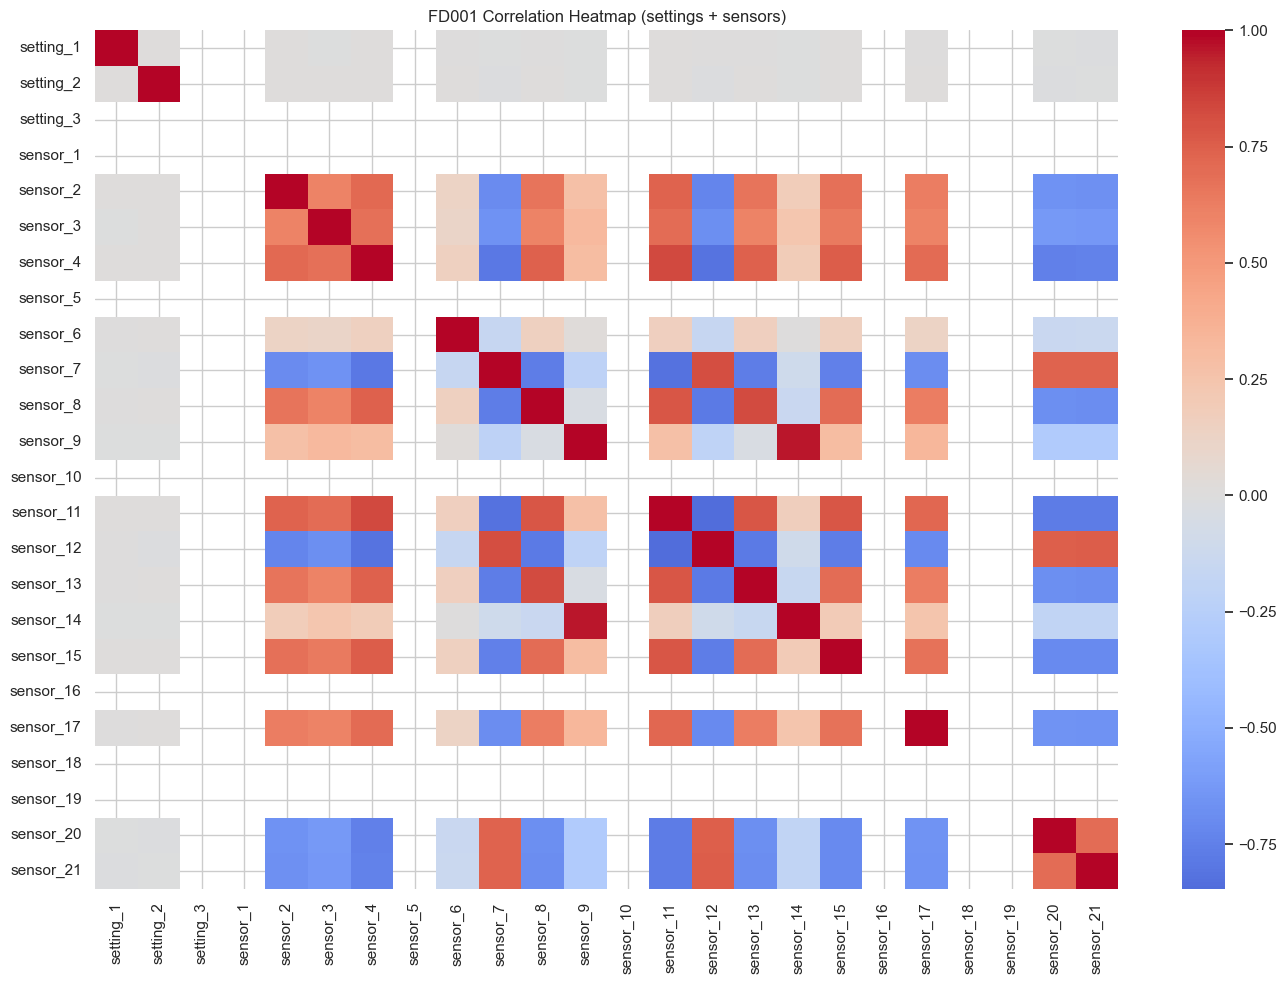

In [12]:
corr_cols = ['setting_1', 'setting_2', 'setting_3'] + SENSOR_COLUMNS
corr_sample = train_df[corr_cols].sample(min(20000, len(train_df)), random_state=42)
corr = corr_sample.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title(f'{focus_ds} Correlation Heatmap (settings + sensors)')
plt.tight_layout()
plt.show()

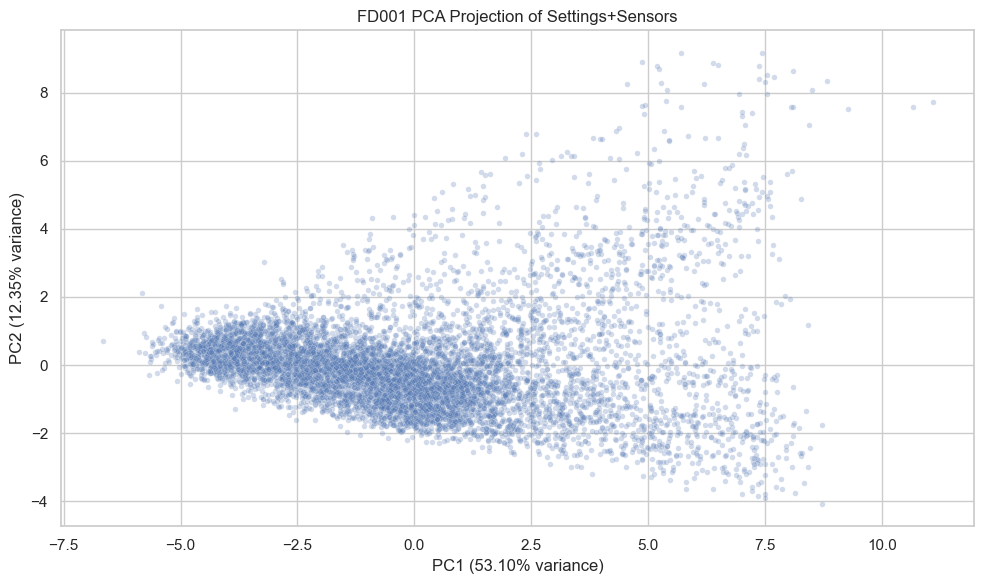

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_features = ['setting_1', 'setting_2', 'setting_3'] + SENSOR_COLUMNS
pca_df = train_df[pca_features].sample(min(25000, len(train_df)), random_state=42).copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_df)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1]
})

plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df.sample(min(8000, len(plot_df)), random_state=42), x='PC1', y='PC2', alpha=0.25, s=16)
plt.title(f'{focus_ds} PCA Projection of Settings+Sensors')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}% variance)')
plt.tight_layout()
plt.show()

In [14]:
eda_out = project_root / 'data' / f'eda_summary_{focus_ds}.csv'
summary_df.to_csv(eda_out, index=False)
print('Saved dataset-level summary to:', eda_out.relative_to(project_root))
summary_df

Saved dataset-level summary to: data/eda_summary_FD001.csv


,dataset,train_rows,test_rows,train_engines,test_engines,train_cycle_min,train_cycle_max,test_cycle_min,test_cycle_max,rul_targets
0,FD001,20631,13096,100,100,1,362,1,303,100
1,FD002,53759,33991,260,259,1,378,1,367,259
2,FD003,24720,16596,100,100,1,525,1,475,100
3,FD004,61249,41214,249,248,1,543,1,486,248


## What the EDA shows

Each row has an engine ID, a cycle, three operating settings and 21 sensor channels. The FD001 plots show that some measurements are constant or nearly constant under one operating condition. The model retains all 24 settings and sensor channels in the same order to preserve the existing input contract across the four subsets. The PCA above is an EDA visualization. Model training uses the original ordered channels.

## Data integrity and training protocol

FD001 and FD003 each represent one operating condition. FD002 and FD004 each use six. FD003 and FD004 include a second simulated fault mode. Multi-source training offsets the unit IDs across subsets and holds out whole engines with seed 42. Training windows end at the label cycle. RUL is the last failure cycle minus that cycle, capped at 125 for training and validation. Test windows use the final observed cycle and repeat the initial observation for histories shorter than 50 cycles.

The feature scaler is fit to training windows only and reused unchanged for validation, every test subset, and Flask inference. Scaler statistics are window-weighted because neighboring training windows overlap. Each test engine contributes one endpoint.

In [15]:
import json
import sys

sys.path.insert(0, str(project_root / 'src'))
from data_loader import load_training_data, train_validation_split
from model import LSTMRULPredictor
import torch

audit = json.loads((data_dir / 'dataset_audit.json').read_text())
quality_fields = ['train_rows', 'test_rows', 'columns', 'train_engines', 'test_engines',
                  'missing_values', 'duplicate_engine_cycles', 'test_rul_above_125']
display(pd.DataFrame({ds: {k: audit['datasets'][ds][k] for k in quality_fields} for ds in subsets}).T)
print('Archive SHA-256:', audit['archive_sha256'])

,train_rows,test_rows,columns,train_engines,test_engines,missing_values,duplicate_engine_cycles,test_rul_above_125
FD001,20631,13096,26,100,100,0,0,11
FD002,53759,33991,26,260,259,0,0,57
FD003,24720,16596,26,100,100,0,0,15
FD004,61249,41214,26,249,248,0,0,67


Archive SHA-256: c9c5dec12a945a82e8bb4446589d7fb3cc057b5e5d81fa1a12e25ee9912ad3b2


## LSTM and model selection

The model has two 64-unit LSTM layers, dropout of 0.2 and one linear output in cycles. Checkpoints are ranked by engine-held-out validation RMSE across validation windows. One targeted configuration used training-only target standardization, batch size 256, norm clipping and validation-driven learning-rate scheduling. The inverse target transform is folded into the existing linear head at export. Test data enters the workflow after each run has picked its checkpoint.

567 training engines / 142 validation engines
56,385 parameters · 50 cycles per window


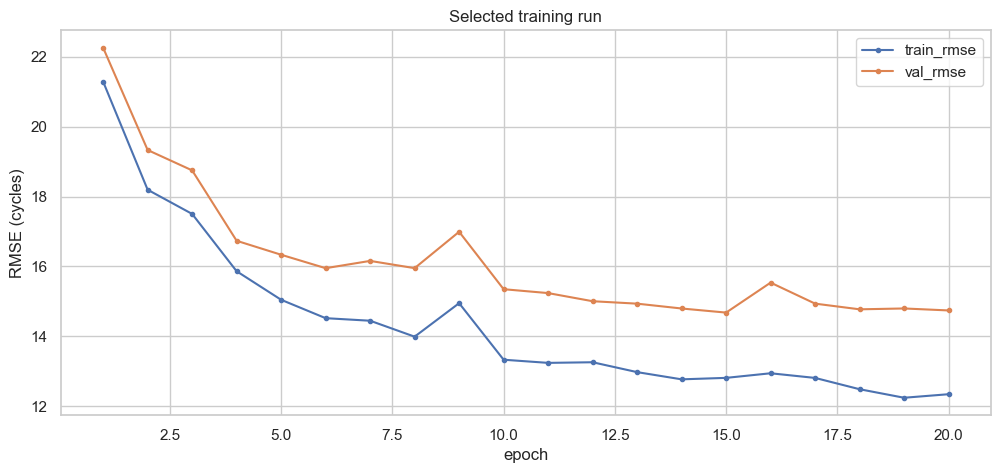

In [16]:
model_dir = project_root / 'models'
current = model_dir / 'current'
legacy = model_dir / 'legacy'
upstream = model_dir / 'upstream'
report = json.loads((current / 'evaluation.json').read_text())
config = report['config']
combined = []
offset = 0
for ds in config['train_datasets']:
    frame = load_training_data(ds)
    frame['unit_id'] += offset
    offset = frame['unit_id'].max()
    combined.append(frame[['unit_id']])
train_ids, val_ids = train_validation_split(pd.concat(combined), config['validation_fraction'], config['seed'])
assert set(train_ids).isdisjoint(val_ids)
assert val_ids == config['validation_ids']
checkpoint = torch.load(current / 'lstm_rul.pth', map_location='cpu', weights_only=True)
model = LSTMRULPredictor(config['input_size'], config['hidden_size'], config['num_layers'], config['dropout'])
model.load_state_dict(checkpoint['state_dict'])
print(f'{len(train_ids)} training engines / {len(val_ids)} validation engines')
print(f"{sum(p.numel() for p in model.parameters()):,} parameters · {config['seq_length']} cycles per window")
history = pd.read_json(current / 'training_history.json')
history.set_index('epoch')[['train_rmse', 'val_rmse']].plot(marker='.', ylabel='RMSE (cycles)', title='Selected training run')
plt.show()

## Regression and residuals

The same deterministic point prediction is compared with both capped and NASA's original uncapped labels. Positive residuals mean the model overestimates available cycles. The NASA score sums exp(−error/13) − 1 for negative errors and exp(error/10) − 1 for positive errors, which penalizes overestimation more heavily. The pooled metrics are computed from all engine predictions together, so the larger subsets have more weight.

engines    rmse     mae     r2  nasa_score  residual_mean  residual_std                        residual_quantiles_05_50_95  \
dataset labels                                                                                                                                 
FD001   capped        100  14.388  10.469  0.871     309.497         -3.222        14.022  [-31.22554702758789, -0.9619941711425781, 18.1...   
        uncapped      100  15.770  11.539  0.856     351.444         -4.292        15.174  [-31.29911880493164, -0.9619941711425781, 18.1...   
FD002   capped        259  13.697   9.623  0.898     881.916         -0.742        13.677  [-22.959745025634763, -1.1979141235351562, 24....   
        uncapped      259  26.396  17.110  0.759    7354.641         -8.236        25.078  [-63.93169250488281, -1.55352783203125, 24.817...   
FD003   capped        100  14.324   9.916  0.866     938.215          1.514        14.243  [-21.024918365478516, 0.4744720458984375, 19.1...   
        uncapped      100  16.153  11.471  0.848    1027.402         -0.046        16.153  [-27.826349639892577, 0.2772102355957031, 19.1...   
FD004   capped        248  15.236  10.895  0.874    1023.767         -1.514        15.160  [-27.87210998535156, 0.29537010192871094, 23.6...   
        uncapped      248  27.536  19.456  0.745    5635.167        -10.208        25.574  [-62.81954231262207, -0.7147407531738281, 23.6...   
pooled  capped        707  14.438  10.230  0.882    3153.395         -1.045        14.400  [-26.081135940551757, -0.634063720703125, 23.8...   
        uncapped      707  24.358  16.347  0.773   14368.654         -7.212        23.266  [-56.70981140136719, -0.8707275390625, 23.8578...   

                  overprediction_rate  
dataset labels                         
FD001   capped                  0.470  
        uncapped                0.470  
FD002   capped                  0.452  
        uncapped                0.444  
FD003   capped                  0.510  
        uncapped                0.500  
FD004   capped                  0.508  
        uncapped                0.484  
pooled  capped                  0.482  
        uncapped                0.470

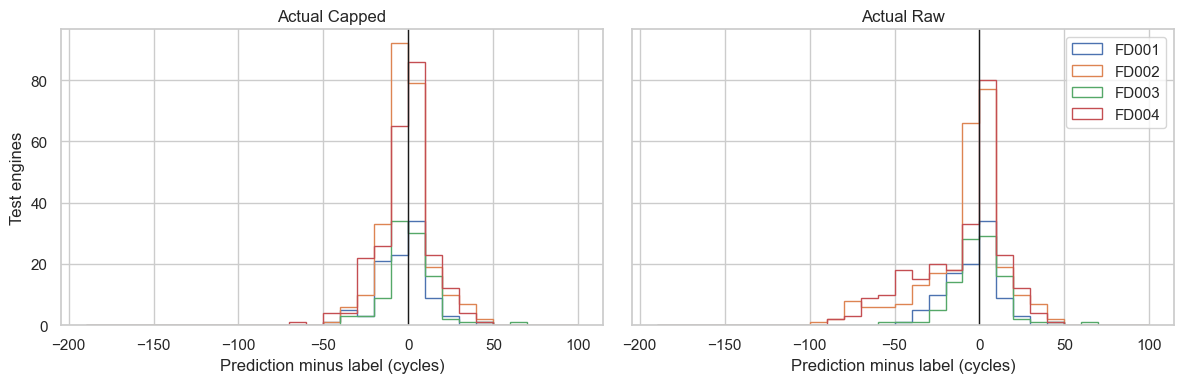

In [17]:
regression_rows = [
    {'dataset': ds, 'labels': label, 'engines': values['engines'], **values[label]}
    for ds, values in report['datasets'].items() for label in ('capped', 'uncapped')
]
display(pd.DataFrame(regression_rows).set_index(['dataset', 'labels']).round(3))
predictions = pd.read_csv(current / 'test_predictions.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col in zip(axes, ['actual_capped', 'actual_raw']):
    for ds, group in predictions.groupby('dataset'):
        ax.hist(group.predicted - group[col], bins=np.arange(-190, 101, 10), histtype='step', label=ds)
    ax.axvline(0, color='k', lw=1)
    ax.set(title=col.replace('_', ' ').title(), xlabel='Prediction minus label (cycles)')
axes[0].set_ylabel('Test engines')
axes[1].legend()
plt.tight_layout()
plt.show()

## Illustrative risk categories

Critical is RUL ≤30 cycles, Warning is 30 < RUL ≤60 cycles, and Healthy is RUL >60 cycles. The categories come directly from the regression prediction and NASA labels. These thresholds are for demonstration on simulated engines and have no aviation safety validation.

FD001 accuracy: 0.900
FD002 accuracy: 0.931
FD003 accuracy: 0.910
FD004 accuracy: 0.931
pooled accuracy: 0.924


precision  recall  f1-score  support
dataset class                                             
FD001   Critical          0.957   0.880     0.917     25.0
        Warning           0.667   0.571     0.615     14.0
        Healthy           0.923   0.984     0.952     61.0
        macro avg         0.849   0.812     0.828    100.0
        weighted avg      0.896   0.900     0.896    100.0
FD002   Critical          0.951   0.951     0.951     61.0
        Warning           0.780   0.780     0.780     41.0
        Healthy           0.962   0.962     0.962    157.0
        macro avg         0.898   0.898     0.898    259.0
        weighted avg      0.931   0.931     0.931    259.0
FD003   Critical          1.000   0.900     0.947     20.0
        Warning           0.833   0.714     0.769     21.0
        Healthy           0.906   0.983     0.943     59.0
        macro avg         0.913   0.866     0.887    100.0
        weighted avg      0.910   0.910     0.907    100.0
FD004   Critical          0.942   0.925     0.933     53.0
        Warning           0.769   0.789     0.779     38.0
        Healthy           0.968   0.968     0.968    157.0
        macro avg         0.893   0.894     0.894    248.0
        weighted avg      0.932   0.931     0.932    248.0
pooled  Critical          0.955   0.925     0.939    159.0
        Warning           0.773   0.746     0.759    114.0
        Healthy           0.950   0.970     0.960    434.0
        macro avg         0.893   0.880     0.886    707.0
        weighted avg      0.923   0.924     0.923    707.0

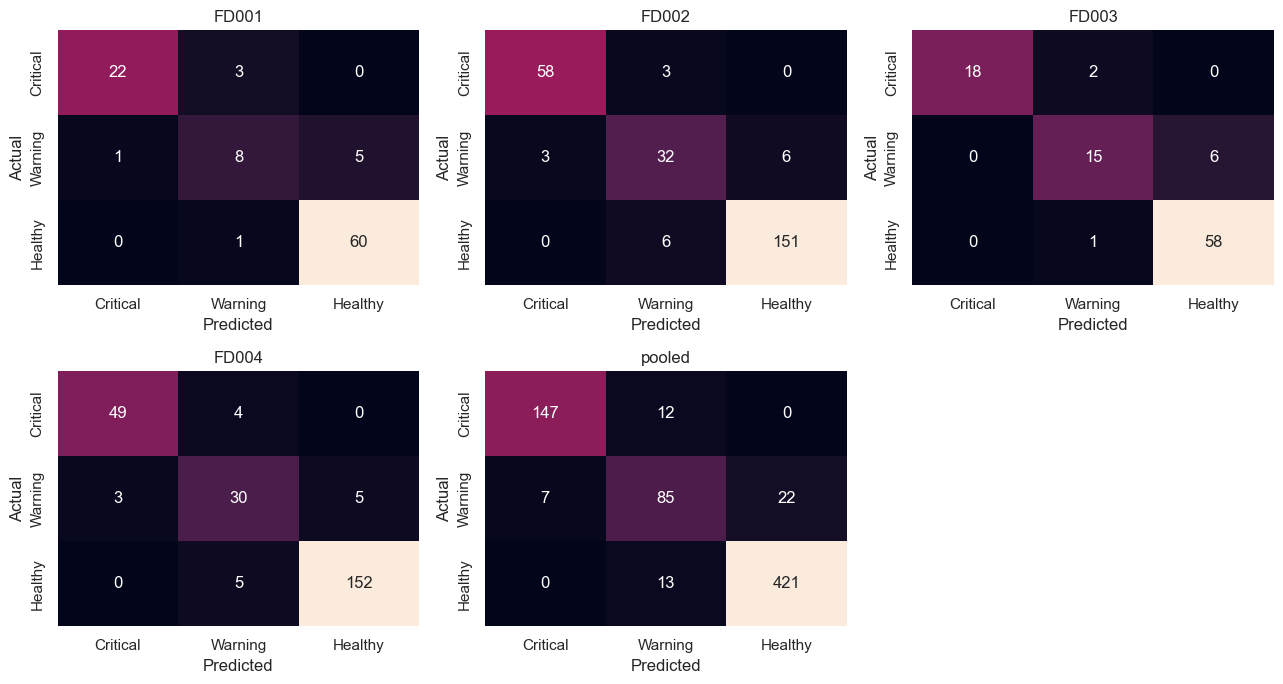

In [18]:
classes = ['Critical', 'Warning', 'Healthy']
classification_rows = []
for ds, values in report['datasets'].items():
    metrics = values['classification']
    print(f"{ds} accuracy: {metrics['accuracy']:.3f}")
    for name in [*classes, 'macro avg', 'weighted avg']:
        classification_rows.append({'dataset': ds, 'class': name, **metrics[name]})
display(pd.DataFrame(classification_rows).set_index(['dataset', 'class']).round(3))
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (ds, values) in zip(axes.flat, report['datasets'].items()):
    sns.heatmap(values['classification']['confusion_matrix'], annot=True, fmt='d', cbar=False,
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set(title=ds, xlabel='Predicted', ylabel='Actual')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

## Predictive uncertainty

MC dropout repeats inference with dropout enabled. The uncalibrated range uses the MC mean ±1.645 standard deviations, with bounds clipped to zero. Validation scaling estimates the 90th-percentile absolute error divided by MC standard deviation (floored at one cycle), using one randomly truncated trajectory per held-out engine. It uses a different multiplier for each label definition. Test coverage is the observed fraction of actual labels inside the interval. Average width is in cycles. Validation engines also support checkpoint selection, and randomly truncated validation trajectories can differ from the official test endpoints. The 90% target has no guaranteed per-engine coverage.

In [19]:
uncertainty_rows = [
    {'dataset': ds, 'labels': label, 'method': method, **measurements}
    for ds, values in report['datasets'].items() for label in ('capped', 'uncapped')
    for method, measurements in values['uncertainty'][label].items()
]
display(pd.DataFrame(uncertainty_rows).set_index(['dataset', 'labels', 'method']).round(3))
print('Validation scale parameters:', report['calibration'])

coverage  average_width  below_interval  above_interval
dataset labels   method                                                                    
FD001   capped   dropout               0.400         11.485           0.220           0.380
                 validation_scaled     0.900         52.064           0.040           0.060
        uncapped dropout               0.400         11.485           0.220           0.380
                 validation_scaled     1.000        190.407           0.000           0.000
FD002   capped   dropout               0.479         12.085           0.216           0.305
                 validation_scaled     0.915         54.435           0.050           0.035
        uncapped dropout               0.417         12.085           0.216           0.367
                 validation_scaled     1.000        199.846           0.000           0.000
FD003   capped   dropout               0.420         11.607           0.320           0.260
                 validation_scaled     0.910         53.370           0.050           0.040
        uncapped dropout               0.350         11.607           0.320           0.330
                 validation_scaled     1.000        195.670           0.000           0.000
FD004   capped   dropout               0.464         12.680           0.242           0.294
                 validation_scaled     0.911         58.594           0.036           0.052
        uncapped dropout               0.359         12.680           0.238           0.403
                 validation_scaled     1.000        209.358           0.000           0.000
pooled  capped   dropout               0.454         12.141           0.240           0.306
                 validation_scaled     0.911         55.408           0.044           0.045
        uncapped dropout               0.385         12.141           0.239           0.376
                 validation_scaled     1.000        201.257           0.000           0.000

Validation scale parameters: {'engines': 142, 'seed': 43, 'mc_samples': 100, 'min_std': 1.0, 'capped_multiplier': 8.209703110859591, 'uncapped_multiplier': 35.68170057782313}


## Original versus selected model

The bundled checkpoint has its own saved training history. The rerun baseline follows the original source and the README's announced 20-epoch budget. Both baselines and the selected checkpoint are scored using this project's common test protocol.

In [20]:
comparison = []
for name, path in [('Bundled original', legacy), ('Original recipe rerun', upstream), ('Selected', current)]:
    file = path / 'evaluation.json'
    if file.is_file():
        run = json.loads(file.read_text())
        for ds, data in run['datasets'].items():
            comparison.append({
                'run': name, 'dataset': ds,
                'best_validation_rmse': run['checkpoint_metrics']['best_val_rmse'],
                'capped_test_rmse': data['capped']['rmse'],
                'uncapped_test_rmse': data['uncapped']['rmse']
            })
display(pd.DataFrame(comparison).set_index(['run', 'dataset']).round(3))

best_validation_rmse  capped_test_rmse  uncapped_test_rmse
run                   dataset                                                            
Bundled original      FD001                  16.228            15.636              16.894
                      FD002                  16.228            14.251              26.195
                      FD003                  16.228            13.970              15.841
                      FD004                  16.228            17.708              28.913
                      pooled                 16.228            15.703              24.909
Original recipe rerun FD001                  15.755            14.184              15.455
                      FD002                  15.755            16.259              28.123
                      FD003                  15.755            14.402              16.199
                      FD004                  15.755            17.504              29.894
                      pooled                 15.755            16.190              25.963
Selected              FD001                  14.677            14.388              15.770
                      FD002                  14.677            13.697              26.396
                      FD003                  14.677            14.324              16.153
                      FD004                  14.677            15.236              27.536
                      pooled                 14.677            14.438              24.358